# Data Loading And Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler,PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

 The dataset is loaded into a Pandas DataFrame for exploration and preprocessing.

 - I combined the `adult.data` file with the `adult.test` file to clean them both once instead of 2 times.

In [2]:
columns = ['age','workclass','fnlwgt','education',
           'education-num','marital-status','occupation','relationship',
           'race','sex','capital-gain','capital-loss',
           'hours-per-week','native-country','income']

df = pd.read_csv('adult.data', names = columns, skipinitialspace=True)

### Data Understanding

In [3]:
df.shape

(48842, 15)

In [4]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
df.tail()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48838,64,?,321403,HS-grad,9,Widowed,?,Other-relative,Black,Male,0,0,40,United-States,<=50K.
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.
48841,35,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K.


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       48842 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      48842 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48842 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [7]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [8]:
df.describe(include='str')

,workclass,education,marital-status,occupation,relationship,race,sex,native-country,income
count,48842,48842,48842,48842,48842,48842,48842,48842,48842
unique,9,16,7,15,6,5,2,42,4
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,33906,15784,22379,6172,19716,41762,32650,43832,24720


### Checking Data Quality

In [9]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

In [10]:
df.replace('?',np.nan,inplace=True)
df.isnull().sum()

age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

### Checking for Missing Values

The dataset uses `?` to represent missing values. These values are converted to `NaN` so that missing data can be identified and handled properly.

In [11]:
percentage = df.isnull().sum() * 100 / df.shape[0]
pd.DataFrame({'Data Type': df.dtypes,
              'Unique Values': df.nunique(),
              'Null Values': df.isnull().sum(),
              'Null Values Percentage': percentage})

,Data Type,Unique Values,Null Values,Null Values Percentage
age,int64,74,0,0.000000
workclass,str,8,2799,5.730724
fnlwgt,int64,28523,0,0.000000
education,str,16,0,0.000000
education-num,int64,16,0,0.000000
marital-status,str,7,0,0.000000
occupation,str,14,2809,5.751198
relationship,str,6,0,0.000000
race,str,5,0,0.000000
sex,str,2,0,0.000000


This shows that the `education-num` is a numerical representation for the `education` column which makes it redundant so we can drop `education` column to avoid dimensionality issues after encoding.

In [12]:
df.duplicated().sum()

np.int64(29)

# Data Cleaning

In [13]:
df.drop(columns='fnlwgt',inplace=True)

`fnlwgt` is a survey sampling weight rather than a meaningful personal characteristic. It represents how many people in the population a particular record is intended to represent, rather than describing the individual's income-related attributes. Therefore, it can be excluded to focus the model on features that directly characterize the individual and are easier to interpret.

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
rows_to_remove = df[df['workclass'].isnull()].index
df.drop(rows_to_remove ,inplace = True)

Rows with missing `workclass` were removed because the corresponding `occupation` values were also missing, making it difficult to reliably infer the individual's employment characteristics. Since both related features were missing, removing these few observations avoids introducing assumptions through imputation.

In [16]:
df[df['occupation'].isnull()].head(20)

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
5361,18,Never-worked,10th,6,Never-married,NaN,Own-child,White,Male,0,0,40,United-States,<=50K
10845,23,Never-worked,7th-8th,4,Divorced,NaN,Not-in-family,White,Male,0,0,35,United-States,<=50K
14772,17,Never-worked,10th,6,Never-married,NaN,Own-child,White,Male,0,0,30,United-States,<=50K
20337,18,Never-worked,11th,7,Never-married,NaN,Own-child,White,Female,0,0,10,United-States,<=50K
23232,20,Never-worked,Some-college,10,Never-married,NaN,Own-child,Black,Male,0,0,40,United-States,<=50K
32304,30,Never-worked,HS-grad,9,Married-civ-spouse,NaN,Wife,Black,Female,0,0,40,United-States,<=50K
32314,18,Never-worked,Some-college,10,Never-married,NaN,Own-child,White,Male,0,0,4,United-States,<=50K
41346,17,Never-worked,11th,7,Never-married,NaN,Own-child,Black,Female,0,0,20,United-States,<=50K.
44168,20,Never-worked,HS-grad,9,Married-spouse-absent,NaN,Other-relative,White,Male,0,0,35,United-States,<=50K.
46459,18,Never-worked,11th,7,Never-married,NaN,Own-child,White,Male,0,0,35,United-States,<=50K.


In [17]:
df['occupation'].value_counts()

occupation
Prof-specialty       5845
Exec-managerial      5644
Adm-clerical         5065
Craft-repair         5050
Sales                5015
Other-service        4541
Machine-op-inspct    2631
Transport-moving     2169
Handlers-cleaners    1833
Farming-fishing      1451
Tech-support         1383
Protective-serv       959
Priv-house-serv       240
Armed-Forces           15
Name: count, dtype: int64

In [18]:
df['occupation'] = df['occupation'].fillna('Never-worked')

The remaining missing `occupation` values were filled with **Never-worked** because `workclass` is available for these records, but the occupation is missing. Since only a very small number of observations are affected, assigning Never-worked prevents unnecessary data loss while providing a meaningful category for the missing occupation.

In [19]:
df['native-country'] = df['native-country'].fillna(df['native-country'].mode()[0])

Missing values in `native-country` were replaced with the mode because it is a categorical feature, and the missing values represent only a small portion of the dataset. Using the most frequent category provides a simple way to retain these observations without introducing an additional category.

In [20]:
df['income'] = df['income'].map({
    '<=50K':'<=50K',
    '>50K': '>50K',
    '<=50K.': '<=50K',
    '>50K.': '>50K' 
})

the `income` column had the same values with different formats so this code makes them only 2 values.

### Final Check

In [21]:
percentage = df.isnull().sum() * 100 / df.shape[0]
pd.DataFrame({'Data Type': df.dtypes,
              'Unique Values': df.nunique(),
              'Null Values': df.isnull().sum(),
              'Null Values Percentage': percentage})

,Data Type,Unique Values,Null Values,Null Values Percentage
age,int64,74,0,0.0
workclass,str,8,0,0.0
education,str,16,0,0.0
education-num,int64,16,0,0.0
marital-status,str,7,0,0.0
occupation,str,15,0,0.0
relationship,str,6,0,0.0
race,str,5,0,0.0
sex,str,2,0,0.0
capital-gain,int64,121,0,0.0


In [22]:
df.head()

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [23]:
df.shape

(41851, 14)

# Visualization and EDA

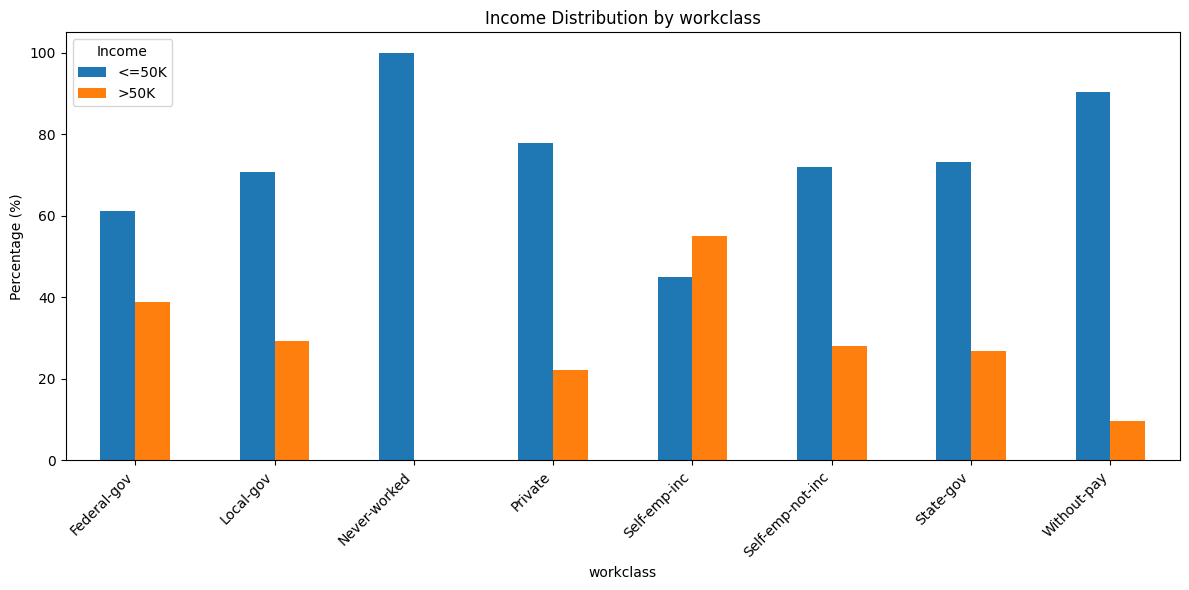

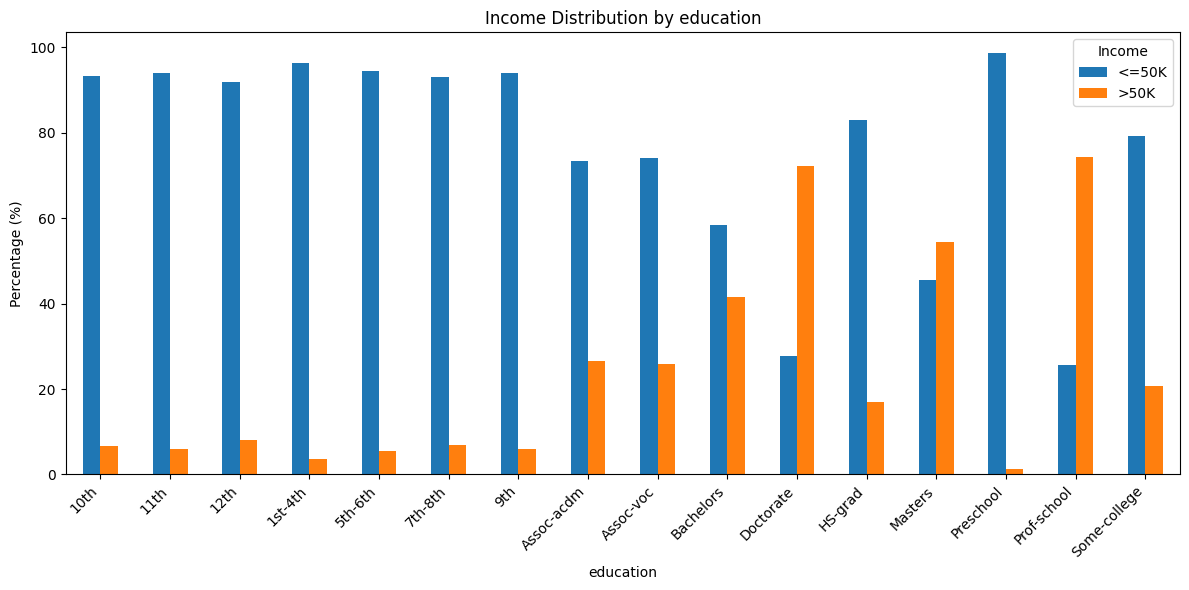

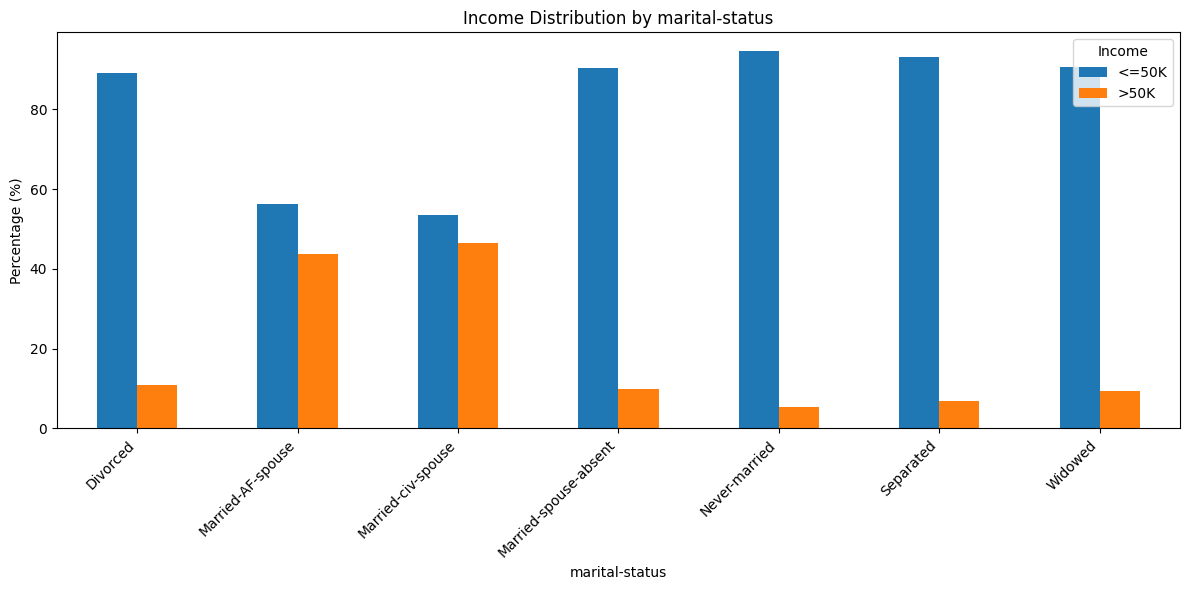

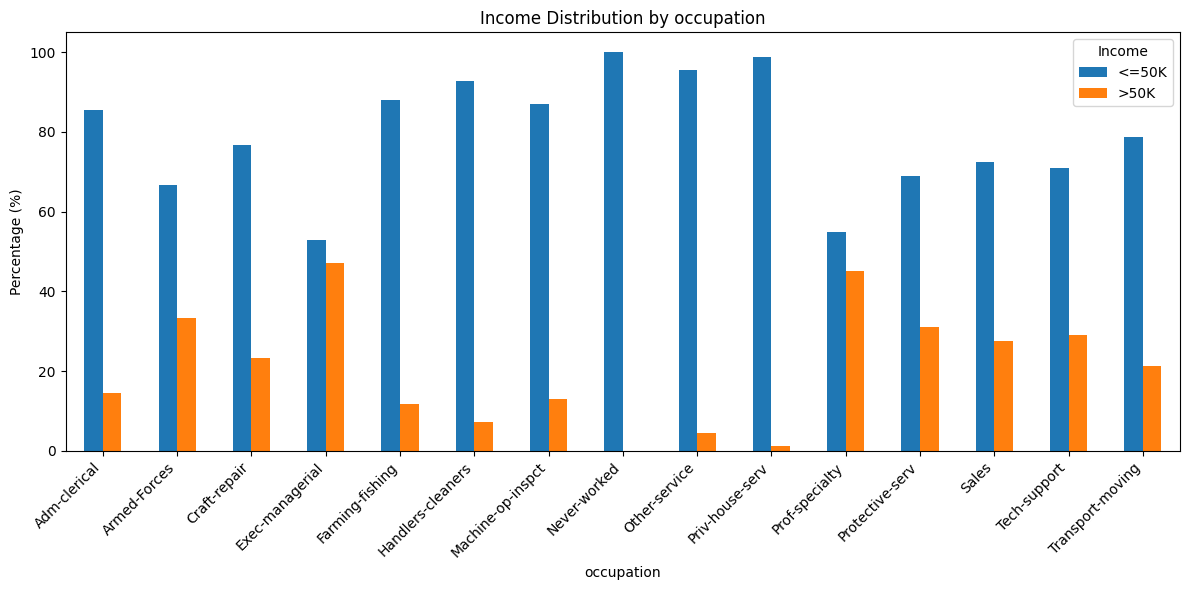

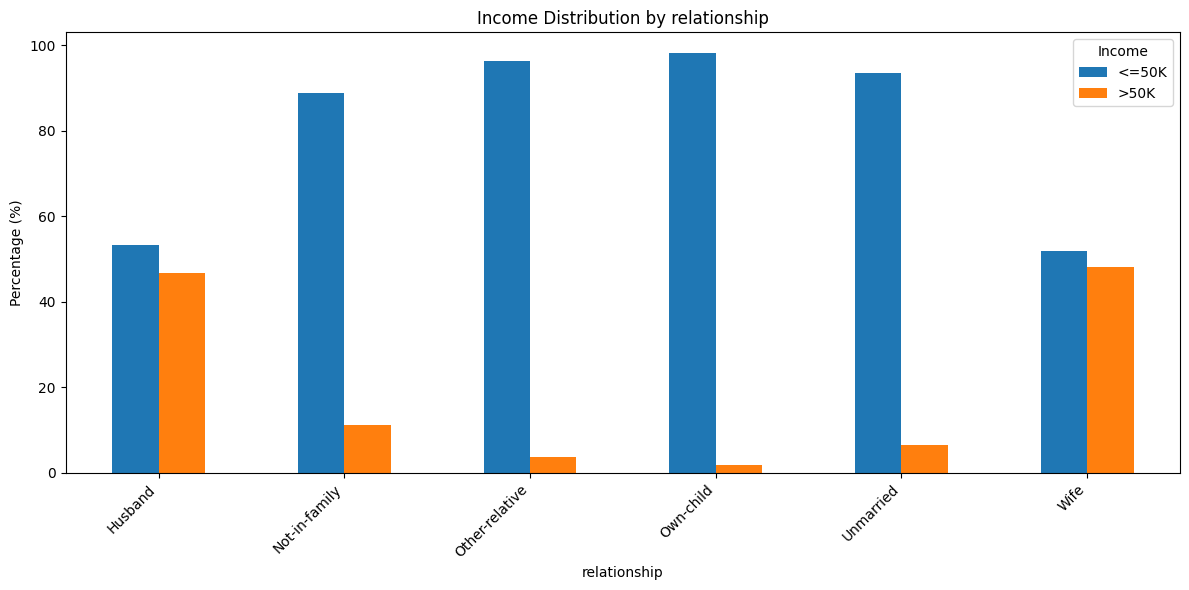

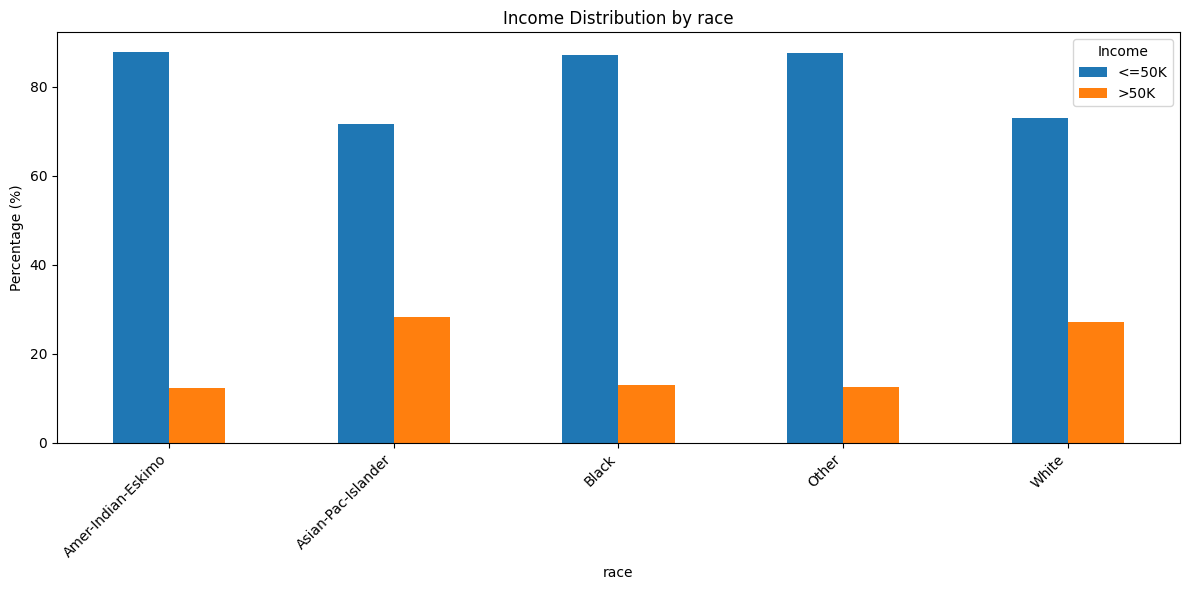

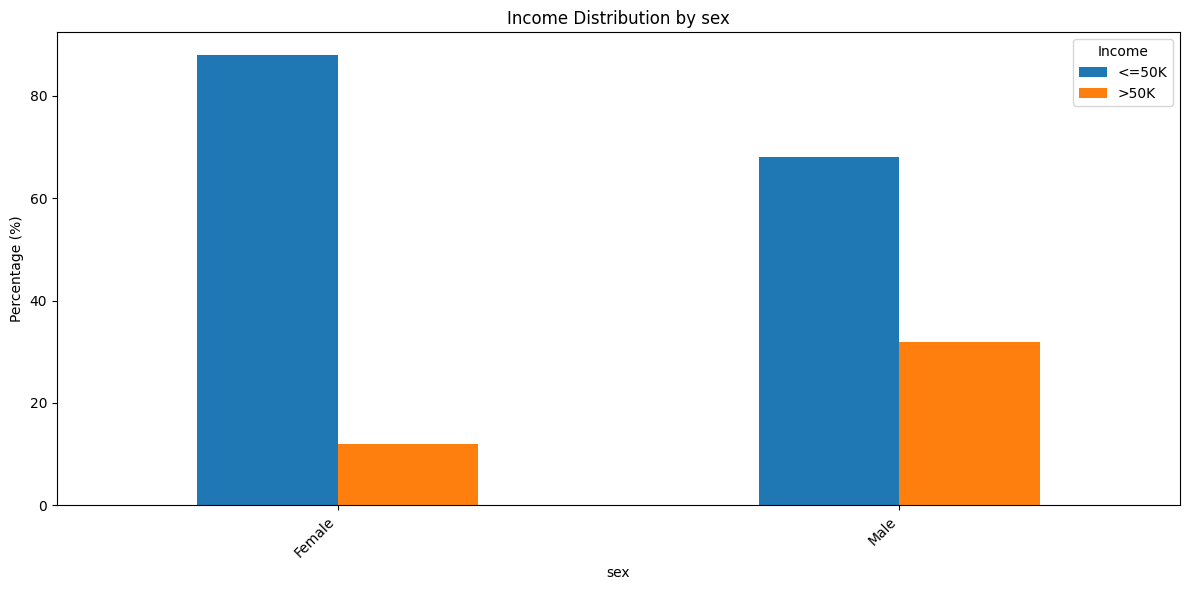

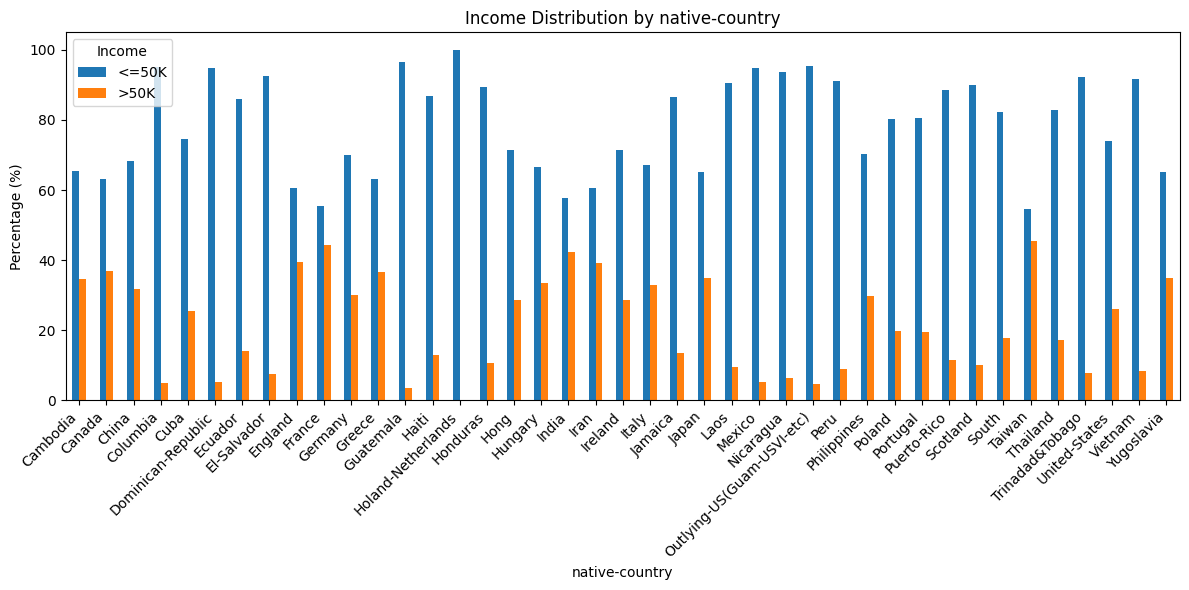

In [24]:
categorical_columns = df.select_dtypes(include='str').columns.tolist()
categorical_columns.remove('income')
for feature in categorical_columns:
    percentage_data = pd.crosstab(
        df[feature],
        df['income'],
        normalize='index'
    ) * 100
    percentage_data.plot(
        kind='bar',
        figsize=(12, 6)
    )
    plt.title(f'Income Distribution by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Percentage (%)')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Income')
    plt.tight_layout()
    plt.show()

### Key Insights from Categorical Feature Visualizations

* `Education`: Higher education levels generally show a greater proportion of individuals earning **>50K**, suggesting that education may be a useful feature for predicting income.

* `Occupation`: Income distributions vary across occupation categories, indicating that occupation may provide useful information for classification.

* `Marital Status`: The proportion of individuals earning **>50K** differs noticeably across marital-status groups, suggesting that this feature may contribute to income classification.

* `Relationship`: Different relationship categories show distinct income distributions, indicating that relationship status may contain useful predictive information.

* `Workclass`: Income proportions vary across workclass categories, although some categories contain relatively few observations and should therefore be interpreted with caution.

* `Sex`: The dataset contains more male than female observations, and the income distribution differs between the two groups. This indicates both class imbalance in the feature and differences in income distribution.

* `Race`: The race categories are unevenly represented in the dataset. Therefore, differences in income distributions should be interpreted while considering the varying sample sizes.

* `Native Country`: This feature contains many categories with substantially different sample sizes. Therefore, raw counts can be dominated by the most common category, making income proportions more informative when comparing categories.


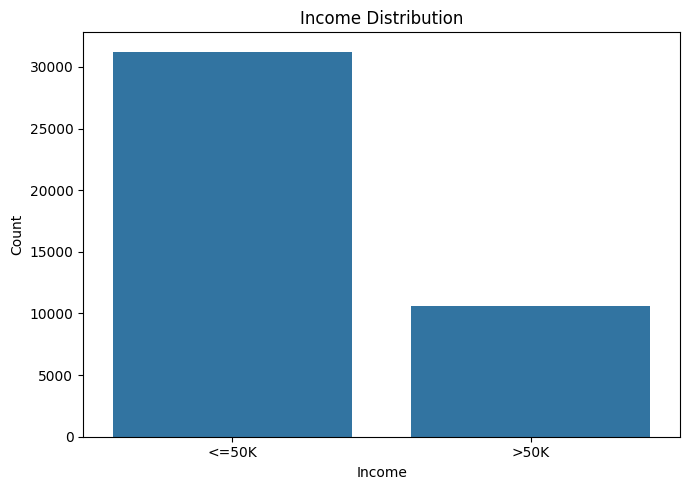

In [25]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='income')
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

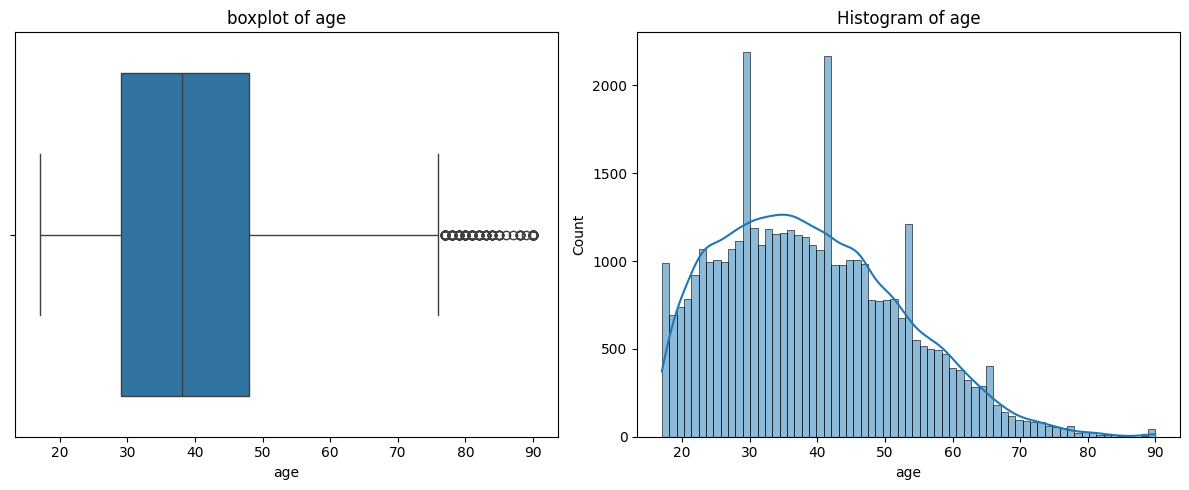

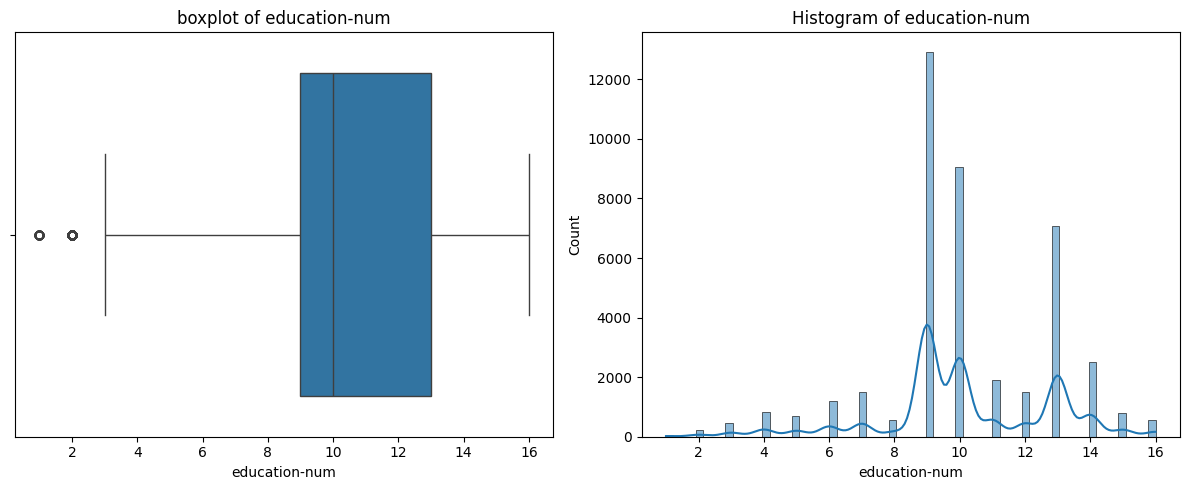

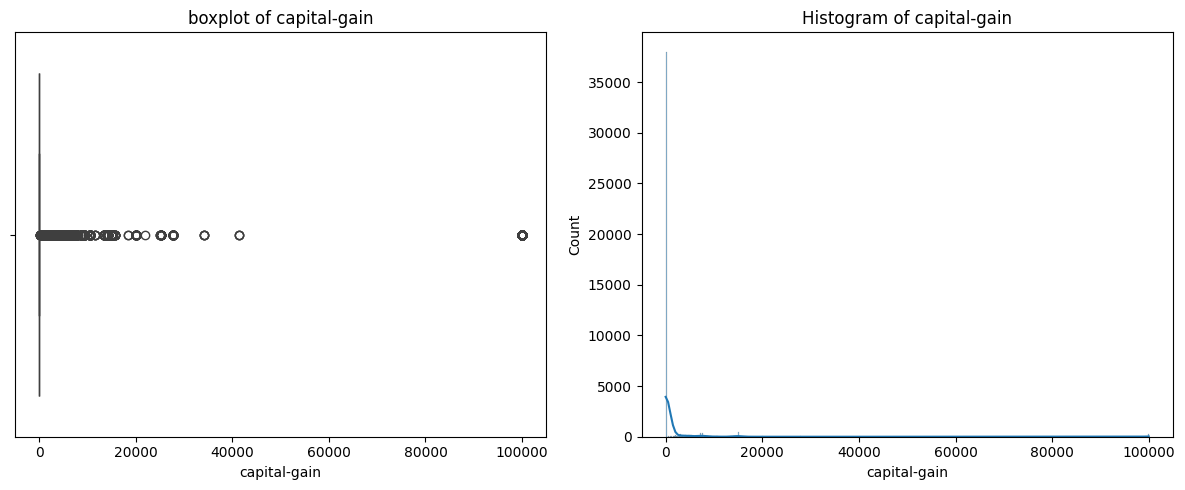

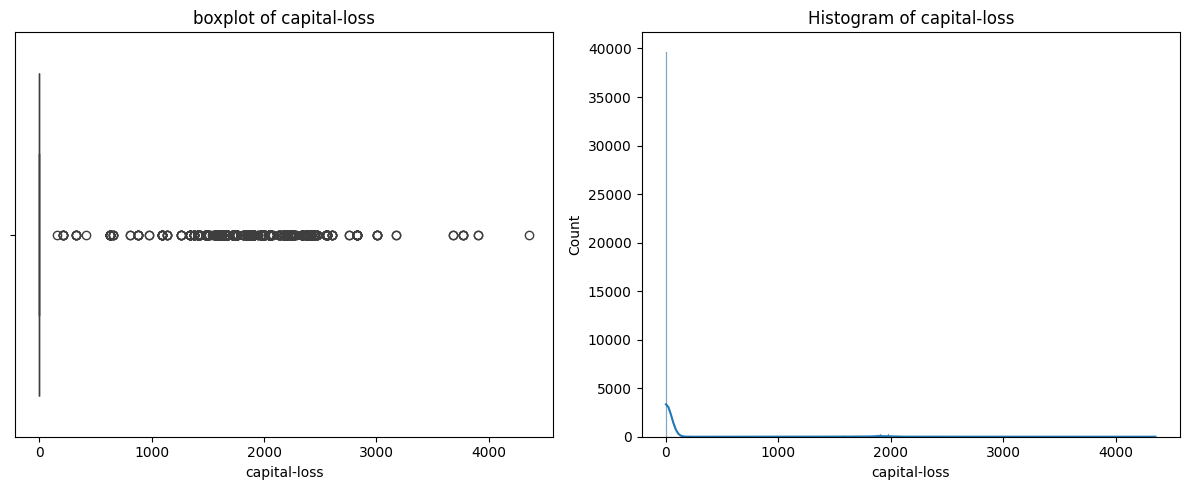

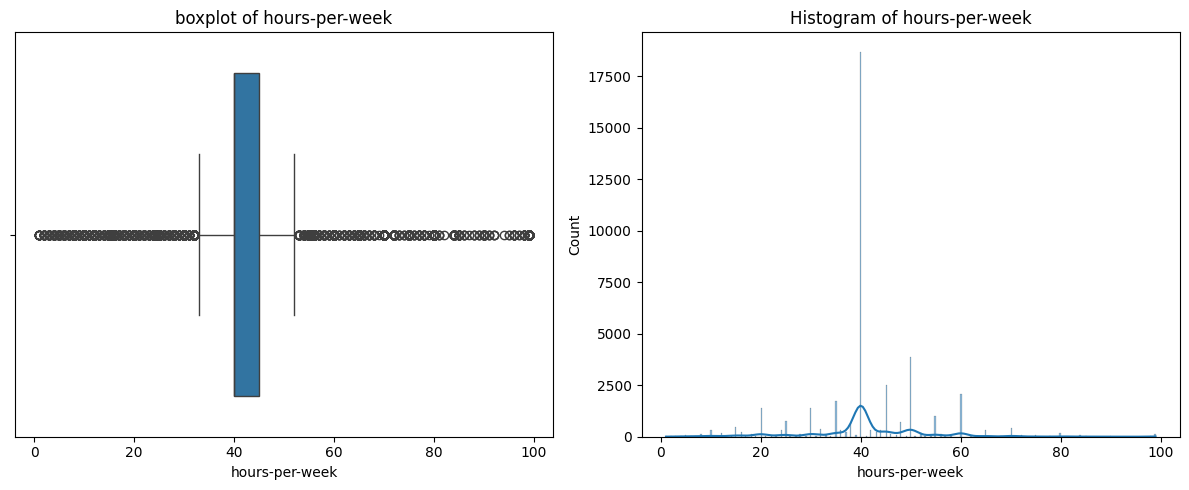

In [26]:
numerical_columns = df.select_dtypes(include='number').columns.tolist()
for i in numerical_columns:
    fig,axes = plt.subplots(1,2,figsize=(12,5))
    sns.boxplot(data=df,x=i,orient='h',ax=axes[0])
    axes[0].set_title(f"boxplot of {i}")
    sns.histplot(data=df,x=i,kde=True,ax=axes[1])
    axes[1].set_title(f"Histogram of {i}")
    plt.tight_layout()
    plt.show()

- The `age` distribution shows that most individuals are within the working-age population, with fewer observations at the younger and older extremes. The boxplot indicates some extreme values, but these represent valid ages rather than data-entry errors.
The apparent outliers in `age` were retained because they represent legitimate individuals at the upper or lower ends of the working-age range. Removing them could result in the loss of valid information.

- No outlier treatment was applied because `education-num` is an ordinal feature with a bounded range, where extreme values correspond to legitimate education levels rather than anomalous observations.

- The `capital-gain` distribution is highly right-skewed, with most observations having zero capital gain and a small number having very large values. These extreme values represent legitimate financial observations, so they were not removed. Instead, the **Yeo-Johnson Power Transformation** was applied to reduce the skewness while preserving the information contained in these observations.

- The `capital-loss` distribution is highly right-skewed, with most observations equal to zero and a small number containing relatively large losses. The extreme values were retained because they represent valid financial observations. The **Yeo-Johnson Power Transformation** was therefore used to reduce the skewness rather than removing these observations.

- The `hours-per-week` distribution is centered around the typical full-time working range, particularly around 40 hours per week. Some observations have unusually low or high working hours, but these can represent legitimate employment situations such as part-time work or overtime. Therefore, the observations were retained without outlier removal.

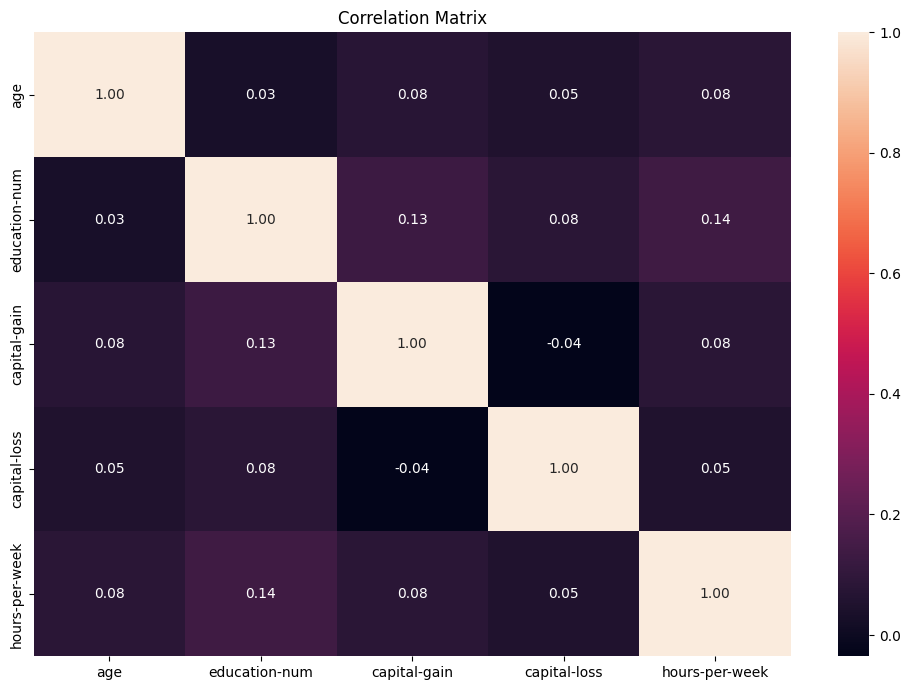

In [27]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include='number').corr(),annot=True,fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [28]:
df.drop(columns='education',inplace=True)
categorical_columns.remove('education')

# Target Variable

The target variable represents income level. It is converted into a binary format:

- `0` → Income ≤ $50K
- `1` → Income > $50K

In [29]:
df['income'] = df['income'].map({
  '<=50K':0,
  '>50K':1,
})

# Preparing Features and Target

The dataset is divided into:

- `x`: input features
- `y`: target variable

In [30]:
x = df.drop(columns='income')
y = df['income']

# Train-Test Split

The dataset is divided into training and testing sets using an 80/20 split.

Stratification is applied to preserve the class distribution in both sets.

In [31]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

# Encoding Categorical Features

Machine learning models require numerical input. Therefore, categorical features are encoded into numerical representations before training.

In [32]:
label_encoder = LabelEncoder()

In [33]:
x_train['native-country'] = label_encoder.fit_transform(x_train['native-country'])
x_test['native-country'] = label_encoder.transform(x_test['native-country'])
x_train['sex'] = label_encoder.fit_transform(x_train['sex'])
x_test['sex'] = label_encoder.transform(x_test['sex'])
categorical_columns.remove('native-country')
categorical_columns.remove('sex')

In [34]:
x_train = pd.get_dummies(
    data=x_train,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

x_test = pd.get_dummies(
    data=x_test,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

In [35]:
x_train, x_test = x_train.align(
    x_test,
    join='left',
    axis=1,
    fill_value=0
)

### Aligning train and test columns

After `one-hot encoding`, `x_train` and `x_test` can end up with different columns (e.g. a category appears in one but not the other). This line fixes that:

- join='left' → use `x_train`'s columns as the reference.
- axis=1 → align columns (not rows).
- fill_value=0 → any column missing in x_test is added and filled with 0.
- Columns in `x_test` not present in `x_train` are dropped.

This ensures `x_test` has exactly the same features, in the same order, as `x_train` — which model.predict() requires.

# Feature Scaling

Logistic Regression can benefit from feature scaling because it is sensitive to the magnitude of the input features.

Decision Trees do not require feature scaling because their splitting process is based on feature thresholds.

Therefore, the scaled features are used for Logistic Regression, while the original numerical representation is sufficient for the Decision Tree.

In [36]:
standard_scaler = StandardScaler()
power_transform = PowerTransformer()

In [37]:
columns_with_outliers_to_handle = ['capital-gain','capital-loss']
numerical_columns.remove('capital-gain')
numerical_columns.remove('capital-loss')

In [38]:
x_train[columns_with_outliers_to_handle] = power_transform.fit_transform(x_train[columns_with_outliers_to_handle])
x_test[columns_with_outliers_to_handle] = power_transform.transform(x_test[columns_with_outliers_to_handle])

In [39]:
x_train[numerical_columns] = standard_scaler.fit_transform(x_train[numerical_columns])
x_test[numerical_columns] = standard_scaler.transform(x_test[numerical_columns])

# Logistic Regression Model

Logistic Regression is used as the first classification model.

A baseline model is trained on the training data and evaluated on the test data.

In [40]:
logReg = LogisticRegression(random_state=42,max_iter=1000)
logReg.fit(x_train,y_train)
y_predict_log = logReg.predict(x_test) 

In [41]:
y_predict_log_train = logReg.predict(x_train)
logReg_baseline_train_accuracy = accuracy_score(y_pred=y_predict_log_train,y_true=y_train)
print("Logistic Regression Training Accuracy Before Tuning:")
logReg_baseline_train_accuracy

Logistic Regression Training Accuracy Before Tuning:


0.8355734767025089

In [42]:
print("Logistic Regression Testing Accuracy Before Tuning:")
logReg_baseline_test_accuracy = accuracy_score(y_pred=y_predict_log,y_true=y_test)
logReg_baseline_test_accuracy

Logistic Regression Testing Accuracy Before Tuning:


0.8326364830964043

### Logistic Regression GridSearch

GridSearchCV is used to search for a better combination of Logistic Regression hyperparameters.

Five-fold cross-validation is used during the search.

In [43]:
logReg_params = {
    'C': [0.01,0.1,1,10],
    'solver': ['lbfgs','liblinear'],
    'max_iter': [2000,5000],
    'class_weight': [None,'balanced']
}

logReg_grid = GridSearchCV(
    estimator=logReg,
    param_grid=logReg_params,
    scoring='accuracy',
    cv=5
)

logReg_grid.fit(x_train,y_train)
logReg_tuned = logReg_grid.best_estimator_
print("Best parameters:", logReg_grid.best_params_)

Best parameters: {'C': 10, 'class_weight': None, 'max_iter': 2000, 'solver': 'lbfgs'}


In [44]:
y_predict_log_tuned_train = logReg_tuned.predict(x_train)
print("logistic Regression Training Accuracy After Tuning:")
logReg_tuned_train_accuracy = accuracy_score(y_pred=y_predict_log_tuned_train,y_true=y_train)
logReg_tuned_train_accuracy

logistic Regression Training Accuracy After Tuning:


0.8356033452807646

In [45]:
y_predict_log_tuned = logReg_tuned.predict(x_test)
print("Logistic Regression Testing Accuracy After Tuning:")
logReg_tuned_test_accuracy = accuracy_score(y_pred=y_predict_log_tuned,y_true=y_test)
logReg_tuned_test_accuracy

Logistic Regression Testing Accuracy After Tuning:


0.832278102974555

### Logistic Regression Model Evaluation Before Tuning

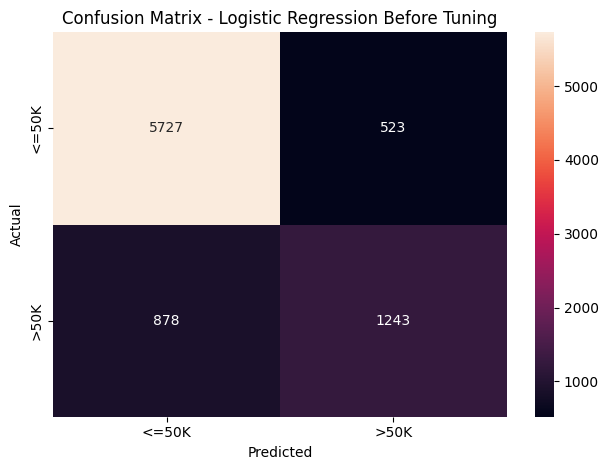

In [46]:
cm = confusion_matrix(y_pred=y_predict_log,y_true=y_test)
sns.heatmap(cm,annot=True,fmt='d',xticklabels=['<=50K', '>50K'],yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression Before Tuning')
plt.tight_layout()
plt.show()

In [47]:
print(classification_report(y_true=y_test,y_pred=y_predict_log))

              precision    recall  f1-score   support

           0       0.87      0.92      0.89      6250
           1       0.70      0.59      0.64      2121

    accuracy                           0.83      8371
   macro avg       0.79      0.75      0.77      8371
weighted avg       0.83      0.83      0.83      8371



### Logistic Regression Model Evaluation After Tuning

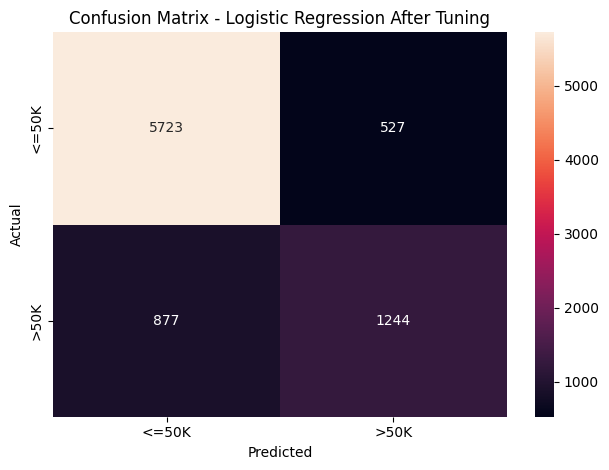

In [48]:
cm = confusion_matrix(y_pred=y_predict_log_tuned,y_true=y_test)
sns.heatmap(cm,annot=True,fmt='d',xticklabels=['<=50K', '>50K'],yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression After Tuning')
plt.tight_layout()
plt.show()

In [49]:
print(classification_report(y_true=y_test,y_pred=y_predict_log_tuned))

              precision    recall  f1-score   support

           0       0.87      0.92      0.89      6250
           1       0.70      0.59      0.64      2121

    accuracy                           0.83      8371
   macro avg       0.78      0.75      0.76      8371
weighted avg       0.83      0.83      0.83      8371



# Decision Tree Model

A Decision Tree Classifier is used as the second classification model.

Unlike Logistic Regression, a Decision Tree can model non-linear relationships by recursively splitting the data according to feature values.

In [50]:
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(x_train,y_train)
y_predict_dt = decision_tree.predict(x_test)

In [51]:
print("Decision Tree Training Accuracy Before Tuning:")
y_predict_dt_train = decision_tree.predict(x_train)
dt_baseline_train_accuracy = accuracy_score(y_pred=y_predict_dt_train,y_true=y_train)
dt_baseline_train_accuracy

Decision Tree Training Accuracy Before Tuning:


0.978405017921147

In [52]:
print("Decision Tree Testing Accuracy Before Tuning:")
dt_baseline_test_accuracy = accuracy_score(y_pred=y_predict_dt,y_true=y_test)
dt_baseline_test_accuracy

Decision Tree Testing Accuracy Before Tuning:


0.7892724883526461

### Decision Tree GridSearch

The Decision Tree is tuned using GridSearchCV to find a better combination of hyperparameters and reduce the risk of overfitting.

Five-fold cross-validation is used during the tuning process.

In [53]:
dt_params = {
    'criterion': ['entropy','gini'],
    'max_depth': [6,8,10,12],
    'min_samples_leaf': [5,10,20],
    'min_samples_split': [10,20,30],
    'class_weight': [None,'balanced']
}

dt_grid = GridSearchCV(
    estimator=decision_tree,
    param_grid=dt_params,
    cv = 5,
    scoring='accuracy'
)

dt_grid.fit(x_train,y_train)
dt_tuned = dt_grid.best_estimator_
print("Best parameters:", dt_grid.best_params_)

Best parameters: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 20, 'min_samples_split': 10}


In [54]:
y_predict_dt_tuned_train = dt_tuned.predict(x_train)
print("Decision Tree Training Accuracy After Tuning:")
dt_tuned_training_acuracy = accuracy_score(y_pred=y_predict_dt_tuned_train,y_true=y_train)
dt_tuned_training_acuracy

Decision Tree Training Accuracy After Tuning:


0.8561827956989247

In [55]:
y_predict_dt_tuned = dt_tuned.predict(x_test)
print("Decision Tree Testing Accuracy After Tuning:")
dt_tuned_test_accuracy = accuracy_score(y_pred=y_predict_dt_tuned,y_true=y_test)
dt_tuned_test_accuracy

Decision Tree Testing Accuracy After Tuning:


0.8404013857364712

### Decision Tree Model Evaluation Before Tuning

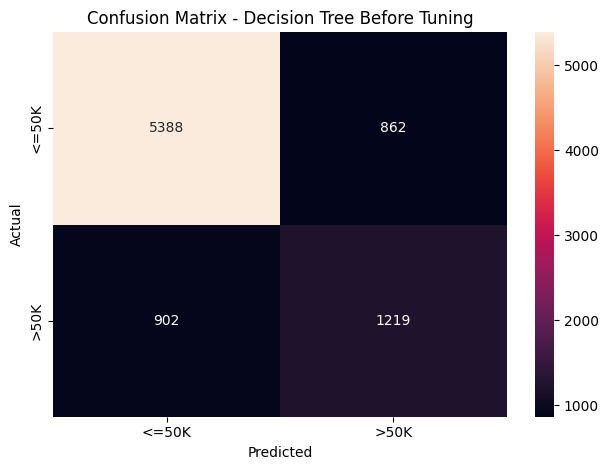

In [56]:
cm = confusion_matrix(y_pred=y_predict_dt,y_true=y_test)
sns.heatmap(cm,annot=True,fmt='d',xticklabels=['<=50K', '>50K'],yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Decision Tree Before Tuning')
plt.tight_layout()
plt.show()

In [57]:
print(classification_report(y_true=y_test,y_pred=y_predict_dt))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86      6250
           1       0.59      0.57      0.58      2121

    accuracy                           0.79      8371
   macro avg       0.72      0.72      0.72      8371
weighted avg       0.79      0.79      0.79      8371



### Decision Tree Model Evaluation After Tuning

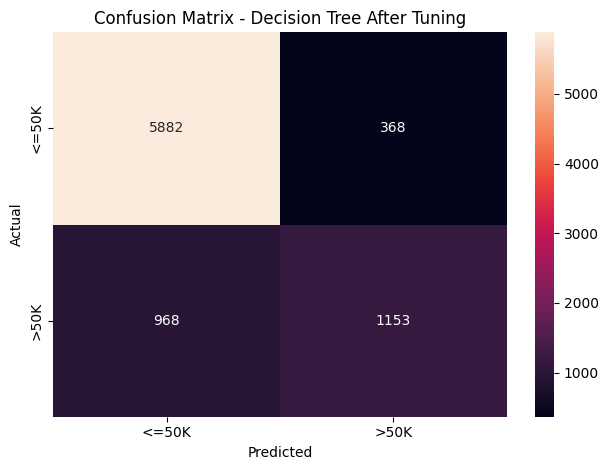

In [58]:
cm = confusion_matrix(y_pred=y_predict_dt_tuned,y_true=y_test)
sns.heatmap(cm,annot=True,fmt='d',xticklabels=['<=50K', '>50K'],yticklabels=['<=50K', '>50K'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Decision Tree After Tuning')
plt.tight_layout()
plt.show()

In [59]:
print(classification_report(y_true=y_test,y_pred=y_predict_dt_tuned))

              precision    recall  f1-score   support

           0       0.86      0.94      0.90      6250
           1       0.76      0.54      0.63      2121

    accuracy                           0.84      8371
   macro avg       0.81      0.74      0.77      8371
weighted avg       0.83      0.84      0.83      8371



# Model Comparison

After training and tuning both models, their performance is compared using the same test set.

The comparison focuses on accuracy, precision, recall, and F1-score. These metrics provide a more complete view of model performance than accuracy alone.

In [60]:
logReg_precision = precision_score(y_test, y_predict_log_tuned)
logReg_recall = recall_score(y_test, y_predict_log_tuned)
logReg_f1 = f1_score(y_test, y_predict_log_tuned)

dt_precision = precision_score(y_test, y_predict_dt_tuned)
dt_recall = recall_score(y_test, y_predict_dt_tuned)
dt_f1 = f1_score(y_test, y_predict_dt_tuned)

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Training Accuracy": [
        logReg_tuned_train_accuracy,
        dt_tuned_training_acuracy
    ],
    "Testing Accuracy": [
        logReg_tuned_test_accuracy,
        dt_tuned_test_accuracy
    ],
    "Precision": [
        logReg_precision,
        dt_precision
    ],
    "Recall": [
        logReg_recall,
        dt_recall
    ],
    "F1-Score": [
        logReg_f1,
        dt_f1
    ]
})

comparison

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.835603,0.832278,0.702428,0.586516,0.639260
1,Decision Tree,0.856183,0.840401,0.758054,0.543612,0.633169


# Performance Comparison

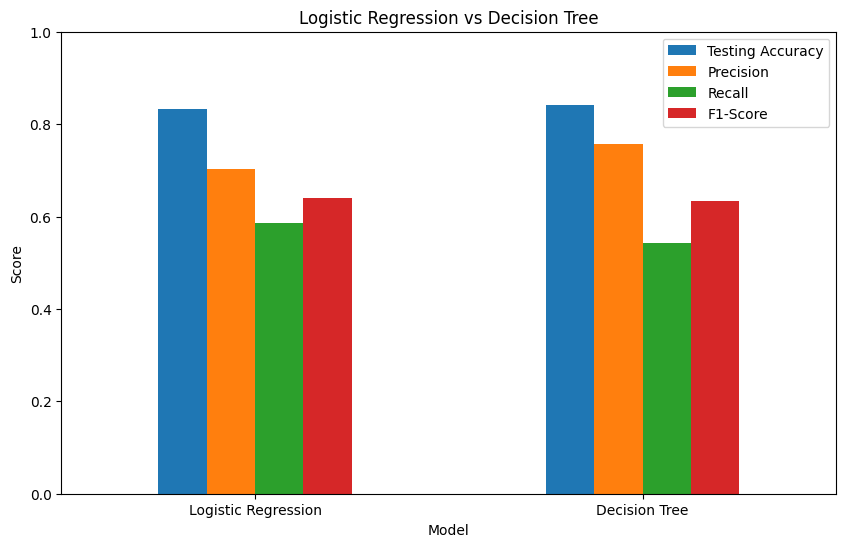

In [61]:
comparison_plot = comparison.set_index("Model")[["Testing Accuracy", "Precision", "Recall", "F1-Score"]]
comparison_plot.plot(kind="bar", figsize=(10, 6))
plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

# Detailed Classification Reports

The classification reports are reviewed to understand how each model performs on both income classes.

In [62]:
print("Logistic Regression:")
print(classification_report(y_test, y_predict_log_tuned))

Logistic Regression:
              precision    recall  f1-score   support

           0       0.87      0.92      0.89      6250
           1       0.70      0.59      0.64      2121

    accuracy                           0.83      8371
   macro avg       0.78      0.75      0.76      8371
weighted avg       0.83      0.83      0.83      8371



In [63]:
print("Decision Tree:")
print(classification_report(y_test, y_predict_dt_tuned))

Decision Tree:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90      6250
           1       0.76      0.54      0.63      2121

    accuracy                           0.84      8371
   macro avg       0.81      0.74      0.77      8371
weighted avg       0.83      0.84      0.83      8371



# Conclusion

* In this project, `Logistic Regression` and `Decision Tree` classifiers were applied to the Adult Income dataset and evaluated using the same test set.

* Both models were tuned using **GridSearchCV with 5-fold cross-validation** to identify suitable hyperparameters and improve their performance.

* The tuned `Decision Tree` achieved a testing accuracy of **84.04%**, compared with **83.23%** for Logistic Regression. It also achieved higher precision (**75.81% vs. 70.24%**).

* However, `Logistic Regression` achieved higher recall (**58.65% vs. 54.36%**) and a slightly higher F1-score (**63.93% vs. 63.32%**) for the **>50K income class**.

* These results show that the two models have similar overall performance but differ in their **precision-recall trade-off**. The Decision Tree makes fewer false-positive predictions for the positive class, while Logistic Regression identifies a larger proportion of the actual positive cases.

* Therefore, evaluating classification models using **multiple metrics rather than accuracy alone** provides a more complete understanding of their performance and limitations.

* Overall, this project demonstrates the complete classification workflow, including **data preprocessing, exploratory analysis, feature transformation, model training, hyperparameter tuning, evaluation, and comparison** of two classification algorithms.


# Final Summary

- `Logistic Regression` and `Decision Tree` were successfully applied to the dataset.
- Both models were evaluated using `accuracy`, `precision`, `recall`, and `F1-score`.
- Both models were tuned using `GridSearchCV` with `5-fold cross-validation`.
- The tuned models were compared using the same test set.
- The results show that the models have similar overall performance but different precision and recall characteristics.